In [3]:
pip install ucimlrepo

In [4]:
from ucimlrepo import fetch_ucirepo
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.feature_selection import f_classif
import numpy as np
import pandas as pd
import os
from scipy.stats import spearmanr, entropy


DATASETS = {
    "Heart Failure": 519,
    "Breast Cancer": 15
}


classifiers = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42),
    "LDA": LDA()
}

# Methods for scoring features
def calculate_feature_scores(X, y, method):
    if method == "Mutual Information":
        scores = mutual_info_classif(X, y)
    elif method == "Linear Correlation":
        scores = np.array([np.corrcoef(X.iloc[:, i], y)[0, 1] for i in range(X.shape[1])])
    elif method == "Spearman Rank Correlation":
        scores = np.array([spearmanr(X.iloc[:, i], y).correlation for i in range(X.shape[1])])
    elif method == "Information Gain":
        scores = f_classif(X, y)[0]
    elif method == "Shannon Entropy":
        scores = np.array([entropy(X.iloc[:, i]) for i in range(X.shape[1])])
    else:
        raise ValueError(f"Unknown method: {method}")
    return scores


def sample_feature_subset(probs, n_features):

    non_zero_indices = np.where(probs > 0)[0]
    if len(non_zero_indices) < n_features:

        n_features = len(non_zero_indices)
    non_zero_probs = probs[non_zero_indices]

    normalized_probs = non_zero_probs / np.sum(non_zero_probs)

    sampled_indices = np.random.choice(non_zero_indices, size=n_features, p=normalized_probs, replace=False)
    return sampled_indices

# Function to run experiments for a single dataset
def run_experiment_for_dataset(dataset_id, dataset_name, methods, n_ensembles=10):
    print(f"\nLoading dataset: {dataset_name} (ID: {dataset_id})")
    try:

        dataset = fetch_ucirepo(id=dataset_id)
        X = dataset.data.features.apply(pd.to_numeric, errors='coerce')
        y = pd.to_numeric(dataset.data.targets.squeeze(), errors='coerce')


        combined = pd.concat([X, y], axis=1)


        combined_dropped = combined.dropna()
        X_dropped = combined_dropped.iloc[:, :-1]
        y = combined_dropped.iloc[:, -1]


        y = pd.factorize(y)[0]


        X_train, X_test, y_train, y_test = train_test_split(X_dropped, y, test_size=0.3, random_state=42)

        final_results = []
        summary_results = []

        for method in methods:
            print(f"\nScoring features using {method}...")
            scores = calculate_feature_scores(X_train, y_train, method)
            probabilities = scores / np.sum(scores)

            \
            max_features = X_train.shape[1]
            min_features = max_features // 2

            for n_features in range(max_features, min_features - 1, -1):
                print(f"\nTraining with {n_features} probabilistic features using method {method}...")
                prob_accuracies = {clf: [] for clf in classifiers.keys()}

                for ensemble in range(n_ensembles):

                    sampled_features = sample_feature_subset(probabilities, n_features)
                    X_train_sampled = X_train.iloc[:, sampled_features]
                    X_test_sampled = X_test.iloc[:, sampled_features]

                    for name, clf in classifiers.items():

                        clf.fit(X_train_sampled, y_train)
                        y_pred = clf.predict(X_test_sampled)
                        prob_accuracy = accuracy_score(y_test, y_pred)


                        final_results.append({
                            "Dataset": dataset_name,
                            "Method": method,
                            "Classifier": name,
                            "n_features": n_features,
                            "Run": ensemble + 1,
                            "Accuracy": prob_accuracy
                        })


                        prob_accuracies[name].append(prob_accuracy)


                for name, accuracies in prob_accuracies.items():
                    summary_results.append({
                        "Dataset": dataset_name,
                        "Method": method,
                        "Classifier": name,
                        "n_features": n_features,
                        "Mean Accuracy": np.mean(accuracies),
                        "Std Accuracy": np.std(accuracies)
                    })


        print("\nTraining with random sampling...")
        for n_features in range(max_features, min_features - 1, -1):
            random_accuracies = {clf: [] for clf in classifiers.keys()}

            for ensemble in range(n_ensembles):
                random_features = np.random.choice(X_train.shape[1], n_features, replace=False)
                X_train_random = X_train.iloc[:, random_features]
                X_test_random = X_test.iloc[:, random_features]

                for name, clf in classifiers.items():
                    clf.fit(X_train_random, y_train)
                    y_pred_rand = clf.predict(X_test_random)
                    random_accuracy = accuracy_score(y_test, y_pred_rand)

                    final_results.append({
                        "Dataset": dataset_name,
                        "Method": "Random Sampling",
                        "Classifier": name,
                        "n_features": n_features,
                        "Run": ensemble + 1,
                        "Accuracy": random_accuracy
                    })

                    random_accuracies[name].append(random_accuracy)


            for name, accuracies in random_accuracies.items():
                summary_results.append({
                    "Dataset": dataset_name,
                    "Method": "Random Sampling",
                    "Classifier": name,
                    "n_features": n_features,
                    "Mean Accuracy": np.mean(accuracies),
                    "Std Accuracy": np.std(accuracies)
                })


        print("\nTraining with all features...")
        all_features_accuracies = {clf: [] for clf in classifiers.keys()}

        for ensemble in range(n_ensembles):
            for name, clf in classifiers.items():
                clf.fit(X_train, y_train)
                y_pred_all = clf.predict(X_test)
                all_features_accuracy = accuracy_score(y_test, y_pred_all)

                final_results.append({
                    "Dataset": dataset_name,
                    "Method": "All Features",
                    "Classifier": name,
                    "n_features": max_features,
                    "Run": ensemble + 1,
                    "Accuracy": all_features_accuracy
                })

                all_features_accuracies[name].append(all_features_accuracy)


        for name, accuracies in all_features_accuracies.items():
            summary_results.append({
                "Dataset": dataset_name,
                "Method": "All Features",
                "Classifier": name,
                "n_features": max_features,
                "Mean Accuracy": np.mean(accuracies),
                "Std Accuracy": np.std(accuracies)
            })


        final_results_df = pd.DataFrame(final_results)
        output_file = f"final_results_{dataset_name.replace(' ', '_').lower()}.csv"
        final_results_df.to_csv(output_file, index=False)


        summary_results_df = pd.DataFrame(summary_results)
        summary_output_file = f"summary_results_{dataset_name.replace(' ', '_').lower()}.csv"
        summary_results_df.to_csv(summary_output_file, index=False)

        print(f"Final results saved to {output_file}")
        print(f"Summary results saved to {summary_output_file}")

    except Exception as e:
        print(f"Failed to run experiment for dataset {dataset_name}. Error: {e}")


methods = [
    "Mutual Information",
    "Linear Correlation",
    "Spearman Rank Correlation",
    "Information Gain",
    "Shannon Entropy"
]


for dataset_name, dataset_id in DATASETS.items():
    run_experiment_for_dataset(dataset_id, dataset_name, methods)



Loading dataset: Heart Failure (ID: 519)

Scoring features using Mutual Information...

Training with 12 probabilistic features using method Mutual Information...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Training with 11 probabilistic features using method Mutual Information...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Training with 10 probabilistic features using method Mutual Information...


...


Training with random sampling...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Training with all features...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Final results saved to final_results_hep_c_(28_features).csv
Summary results saved to summary_results_hep_c_(28_features).csv

Loading dataset: Breast Cancer (ID: 15)

Scoring features using Mutual Information...

Training with 9 probabilistic features using method Mutual Information...

Training with 8 probabilistic features using method Mutual Information...

Training with 7 probabilistic features using method Mutual Information...

Training with 6 probabilistic features using method Mutual Information...

Training with 5 probabilistic features using method Mutual Information...

Training with 4 probabilistic features using method Mutual Information...

Scoring features using Linear Correlation...

Training with 9 probabilistic features using method Linear Correlation...

Training with 8 probabilistic features using method Linear Correlation...

Training with 7 probabilistic features using method Linear Correlation...

Training with 6 probabilistic features using method Linear Correl

In [7]:
from ucimlrepo import fetch_ucirepo
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import f_classif
import numpy as np
import pandas as pd
import os
from scipy.stats import spearmanr, entropy

DATASETS = {
    "Liver Disorder": 145
}

classifiers = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42),
    "LDA": LDA()
}

def calculate_feature_scores(X, y, method):
    if method == "Mutual Information":
        scores = mutual_info_classif(X, y)
    elif method == "Linear Correlation":
        scores = np.array([np.corrcoef(X.iloc[:, i], y)[0, 1] for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    elif method == "Spearman Rank Correlation":
        scores = np.array([spearmanr(X.iloc[:, i], y).correlation for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    elif method == "Information Gain":
        scores = f_classif(X, y)[0]
    elif method == "Shannon Entropy":
        scores = np.array([entropy(X.iloc[:, i]) for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    else:
        raise ValueError(f"Unknown method: {method}")
    return scores

def normalize_probabilities(scores):
    total = np.sum(scores)
    if total == 0:
        return np.ones(len(scores)) / len(scores)
    return scores / total

def sample_feature_subset(probs, n_features):
    non_zero_indices = np.where(probs > 0)[0]
    if len(non_zero_indices) < n_features:
        n_features = len(non_zero_indices)
    non_zero_probs = probs[non_zero_indices]
    normalized_probs = non_zero_probs / np.sum(non_zero_probs)
    sampled_indices = np.random.choice(non_zero_indices, size=n_features, p=normalized_probs, replace=False)
    return sampled_indices

def run_experiment_for_dataset(dataset_id, dataset_name, methods, n_ensembles=10):
    print(f"\nLoading dataset: {dataset_name} (ID: {dataset_id})")
    try:
        dataset = fetch_ucirepo(id=dataset_id)
        X = dataset.data.features.apply(pd.to_numeric, errors='coerce')
        y = pd.to_numeric(dataset.data.targets.squeeze(), errors='coerce')
        combined = pd.concat([X, y], axis=1)
        combined_dropped = combined.dropna()
        X_dropped = combined_dropped.iloc[:, :-1]
        y = combined_dropped.iloc[:, -1]
        y = pd.factorize(y)[0]
        X_train, X_test, y_train, y_test = train_test_split(X_dropped, y, test_size=0.3, random_state=42)
        final_results = []
        summary_results = []
        for method in methods:
            print(f"\nScoring features using {method}...")
            scores = calculate_feature_scores(X_train, y_train, method)
            probabilities = normalize_probabilities(scores)
            max_features = X_train.shape[1]
            min_features = max_features // 2
            for n_features in range(max_features, min_features - 1, -1):
                print(f"\nTraining with {n_features} probabilistic features using method {method}...")
                prob_accuracies = {clf: [] for clf in classifiers.keys()}
                for ensemble in range(n_ensembles):
                    sampled_features = sample_feature_subset(probabilities, n_features)
                    X_train_sampled = X_train.iloc[:, sampled_features]
                    X_test_sampled = X_test.iloc[:, sampled_features]
                    for name, clf in classifiers.items():
                        clf.fit(X_train_sampled, y_train)
                        y_pred = clf.predict(X_test_sampled)
                        prob_accuracy = accuracy_score(y_test, y_pred)
                        final_results.append({
                            "Dataset": dataset_name,
                            "Method": method,
                            "Classifier": name,
                            "n_features": n_features,
                            "Run": ensemble + 1,
                            "Accuracy": prob_accuracy
                        })
                        prob_accuracies[name].append(prob_accuracy)
                for name, accuracies in prob_accuracies.items():
                    summary_results.append({
                        "Dataset": dataset_name,
                        "Method": method,
                        "Classifier": name,
                        "n_features": n_features,
                        "Mean Accuracy": np.mean(accuracies),
                        "Std Accuracy": np.std(accuracies)
                    })
        print("\nTraining with random sampling...")
        for n_features in range(max_features, min_features - 1, -1):
            random_accuracies = {clf: [] for clf in classifiers.keys()}
            for ensemble in range(n_ensembles):
                random_features = np.random.choice(X_train.shape[1], n_features, replace=False)
                X_train_random = X_train.iloc[:, random_features]
                X_test_random = X_test.iloc[:, random_features]
                for name, clf in classifiers.items():
                    clf.fit(X_train_random, y_train)
                    y_pred_rand = clf.predict(X_test_random)
                    random_accuracy = accuracy_score(y_test, y_pred_rand)
                    final_results.append({
                        "Dataset": dataset_name,
                        "Method": "Random Sampling",
                        "Classifier": name,
                        "n_features": n_features,
                        "Run": ensemble + 1,
                        "Accuracy": random_accuracy
                    })
                    random_accuracies[name].append(random_accuracy)
            for name, accuracies in random_accuracies.items():
                summary_results.append({
                    "Dataset": dataset_name,
                    "Method": "Random Sampling",
                    "Classifier": name,
                    "n_features": n_features,
                    "Mean Accuracy": np.mean(accuracies),
                    "Std Accuracy": np.std(accuracies)
                })
        print("\nTraining with all features...")
        all_features_accuracies = {clf: [] for clf in classifiers.keys()}
        for ensemble in range(n_ensembles):
            for name, clf in classifiers.items():
                clf.fit(X_train, y_train)
                y_pred_all = clf.predict(X_test)
                all_features_accuracy = accuracy_score(y_test, y_pred_all)
                final_results.append({
                    "Dataset": dataset_name,
                    "Method": "All Features",
                    "Classifier": name,
                    "n_features": max_features,
                    "Run": ensemble + 1,
                    "Accuracy": all_features_accuracy
                })
                all_features_accuracies[name].append(all_features_accuracy)
        for name, accuracies in all_features_accuracies.items():
            summary_results.append({
                "Dataset": dataset_name,
                "Method": "All Features",
                "Classifier": name,
                "n_features": max_features,
                "Mean Accuracy": np.mean(accuracies),
                "Std Accuracy": np.std(accuracies)
            })
        final_results_df = pd.DataFrame(final_results)
        output_file = f"final_results_{dataset_name.replace(' ', '_').lower()}.csv"
        final_results_df.to_csv(output_file, index=False)
        summary_results_df = pd.DataFrame(summary_results)
        summary_output_file = f"summary_results_{dataset_name.replace(' ', '_').lower()}.csv"
        summary_results_df.to_csv(summary_output_file, index=False)
        print(f"Final results saved to {output_file}")
        print(f"Summary results saved to {summary_output_file}")
    except Exception as e:
        print(f"Failed to run experiment for dataset {dataset_name}. Error: {e}")

methods = [
    "Mutual Information",
    "Linear Correlation",
    "Spearman Rank Correlation",
    "Information Gain",
    "Shannon Entropy"
]

for dataset_name, dataset_id in DATASETS.items():
    run_experiment_for_dataset(dataset_id, dataset_name, methods)



Loading dataset: Liver Disorder (ID: 145)

Scoring features using Mutual Information...

Training with 13 probabilistic features using method Mutual Information...

Training with 12 probabilistic features using method Mutual Information...

Training with 11 probabilistic features using method Mutual Information...

Training with 10 probabilistic features using method Mutual Information...

Training with 9 probabilistic features using method Mutual Information...

Training with 8 probabilistic features using method Mutual Information...

Training with 7 probabilistic features using method Mutual Information...

Training with 6 probabilistic features using method Mutual Information...

Scoring features using Linear Correlation...

Training with 13 probabilistic features using method Linear Correlation...

Training with 12 probabilistic features using method Linear Correlation...

Training with 11 probabilistic features using method Linear Correlation...

Training with 10 probabilistic f

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Training with 12 probabilistic features using method Information Gain...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Training with 11 probabilistic features using method Information Gain...

Training with 10 probabilistic features using method Information Gain...

Training with 9 probabilistic features using method Information Gain...

Training with 8 probabilistic features using method Information Gain...

Training with 7 probabilistic features using method Information Gain...

Training with 6 probabilistic features using method Information Gain...

Scoring features using Shannon Entropy...

Training with 13 probabilistic features using method Shannon Entropy...


...


Training with 11 probabilistic features using method Shannon Entropy...

Training with 10 probabilistic features using method Shannon Entropy...

Training with 9 probabilistic features using method Shannon Entropy...

Training with 8 probabilistic features using method Shannon Entropy...

Training with 7 probabilistic features using method Shannon Entropy...

Training with 6 probabilistic features using method Shannon Entropy...

Training with random sampling...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Training with all features...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Final results saved to final_results_liver_disorder.csv
Summary results saved to summary_results_liver_disorder.csv

Loading dataset: Diabetes (ID: 37)
Failed to run experiment for dataset Diabetes. Error: "EBL Domain Theories" dataset (id=37) exists in the repository, but is not available for import. Please select a dataset from this list: https://archive.ics.uci.edu/datasets?skip=0&take=10&sort=desc&orderBy=NumHits&search=&Python=true


In [2]:
from ucimlrepo import fetch_ucirepo
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.feature_selection import f_classif
import numpy as np
import pandas as pd
import os
from scipy.stats import spearmanr, entropy


DATASETS = {
    "Breast Cancer Wisconsin": 15
}


classifiers = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42),
    "LDA": LDA()
}


def calculate_feature_scores(X, y, method):
    if method == "Mutual Information":
        scores = mutual_info_classif(X, y)
    elif method == "Linear Correlation":
        scores = np.array([np.corrcoef(X.iloc[:, i], y)[0, 1] for i in range(X.shape[1])])

        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    elif method == "Spearman Rank Correlation":
        scores = np.array([spearmanr(X.iloc[:, i], y).correlation for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    elif method == "Information Gain":
        scores = f_classif(X, y)[0]
    elif method == "Shannon Entropy":
        scores = np.array([entropy(X.iloc[:, i]) for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    else:
        raise ValueError(f"Unknown method: {method}")
    return scores


def normalize_probabilities(scores):
    total = np.sum(scores)
    if total == 0:

        return np.ones(len(scores)) / len(scores)
    return scores / total


def sample_feature_subset(probs, n_features):

    non_zero_indices = np.where(probs > 0)[0]
    if len(non_zero_indices) < n_features:

        n_features = len(non_zero_indices)
    non_zero_probs = probs[non_zero_indices]

    normalized_probs = non_zero_probs / np.sum(non_zero_probs)

    sampled_indices = np.random.choice(non_zero_indices, size=n_features, p=normalized_probs, replace=False)
    return sampled_indices

def run_experiment_for_dataset(dataset_id, dataset_name, methods, n_ensembles=10):
    print(f"\nLoading dataset: {dataset_name} (ID: {dataset_id})")
    try:

        dataset = fetch_ucirepo(id=dataset_id)
        X = dataset.data.features.apply(pd.to_numeric, errors='coerce')
        y = pd.to_numeric(dataset.data.targets.squeeze(), errors='coerce')


        combined = pd.concat([X, y], axis=1)


        combined_dropped = combined.dropna()
        X_dropped = combined_dropped.iloc[:, :-1]
        y = combined_dropped.iloc[:, -1]


        y = pd.factorize(y)[0]


        X_train, X_test, y_train, y_test = train_test_split(X_dropped, y, test_size=0.3, random_state=42)

        final_results = []
        summary_results = []

        for method in methods:
            print(f"\nScoring features using {method}...")
            scores = calculate_feature_scores(X_train, y_train, method)
            probabilities = normalize_probabilities(scores)


            max_features = X_train.shape[1]
            min_features = max_features // 2

            for n_features in range(max_features, min_features - 1, -1):
                print(f"\nTraining with {n_features} probabilistic features using method {method}...")
                prob_accuracies = {clf: [] for clf in classifiers.keys()}

                for ensemble in range(n_ensembles):

                    sampled_features = sample_feature_subset(probabilities, n_features)
                    X_train_sampled = X_train.iloc[:, sampled_features]
                    X_test_sampled = X_test.iloc[:, sampled_features]

                    for name, clf in classifiers.items():

                        clf.fit(X_train_sampled, y_train)
                        y_pred = clf.predict(X_test_sampled)
                        prob_accuracy = accuracy_score(y_test, y_pred)


                        final_results.append({
                            "Dataset": dataset_name,
                            "Method": method,
                            "Classifier": name,
                            "n_features": n_features,
                            "Run": ensemble + 1,
                            "Accuracy": prob_accuracy
                        })


                        prob_accuracies[name].append(prob_accuracy)


                for name, accuracies in prob_accuracies.items():
                    summary_results.append({
                        "Dataset": dataset_name,
                        "Method": method,
                        "Classifier": name,
                        "n_features": n_features,
                        "Mean Accuracy": np.mean(accuracies),
                        "Std Accuracy": np.std(accuracies)
                    })


        print("\nTraining with random sampling...")
        for n_features in range(max_features, min_features - 1, -1):
            random_accuracies = {clf: [] for clf in classifiers.keys()}

            for ensemble in range(n_ensembles):
                random_features = np.random.choice(X_train.shape[1], n_features, replace=False)
                X_train_random = X_train.iloc[:, random_features]
                X_test_random = X_test.iloc[:, random_features]

                for name, clf in classifiers.items():
                    clf.fit(X_train_random, y_train)
                    y_pred_rand = clf.predict(X_test_random)
                    random_accuracy = accuracy_score(y_test, y_pred_rand)

                    final_results.append({
                        "Dataset": dataset_name,
                        "Method": "Random Sampling",
                        "Classifier": name,
                        "n_features": n_features,
                        "Run": ensemble + 1,
                        "Accuracy": random_accuracy
                    })

                    random_accuracies[name].append(random_accuracy)


            for name, accuracies in random_accuracies.items():
                summary_results.append({
                    "Dataset": dataset_name,
                    "Method": "Random Sampling",
                    "Classifier": name,
                    "n_features": n_features,
                    "Mean Accuracy": np.mean(accuracies),
                    "Std Accuracy": np.std(accuracies)
                })


        print("\nTraining with all features...")
        all_features_accuracies = {clf: [] for clf in classifiers.keys()}

        for ensemble in range(n_ensembles):
            for name, clf in classifiers.items():
                clf.fit(X_train, y_train)
                y_pred_all = clf.predict(X_test)
                all_features_accuracy = accuracy_score(y_test, y_pred_all)

                final_results.append({
                    "Dataset": dataset_name,
                    "Method": "All Features",
                    "Classifier": name,
                    "n_features": max_features,
                    "Run": ensemble + 1,
                    "Accuracy": all_features_accuracy
                })

                all_features_accuracies[name].append(all_features_accuracy)


        for name, accuracies in all_features_accuracies.items():
            summary_results.append({
                "Dataset": dataset_name,
                "Method": "All Features",
                "Classifier": name,
                "n_features": max_features,
                "Mean Accuracy": np.mean(accuracies),
                "Std Accuracy": np.std(accuracies)
            })

        final_results_df = pd.DataFrame(final_results)
        output_file = f"final_results_{dataset_name.replace(' ', '_').lower()}.csv"
        final_results_df.to_csv(output_file, index=False)


        summary_results_df = pd.DataFrame(summary_results)
        summary_output_file = f"summary_results_{dataset_name.replace(' ', '_').lower()}.csv"
        summary_results_df.to_csv(summary_output_file, index=False)

        print(f"Final results saved to {output_file}")
        print(f"Summary results saved to {summary_output_file}")

    except Exception as e:
        print(f"Failed to run experiment for dataset {dataset_name}. Error: {e}")


methods = [
    "Mutual Information",
    "Linear Correlation",
    "Spearman Rank Correlation",
    "Information Gain",
    "Shannon Entropy"
]


for dataset_name, dataset_id in DATASETS.items():
    run_experiment_for_dataset(dataset_id, dataset_name, methods)



Loading dataset: Breast Cancer Wisconsin (ID: 15)

Scoring features using Mutual Information...

Training with 9 probabilistic features using method Mutual Information...

Training with 8 probabilistic features using method Mutual Information...

Training with 7 probabilistic features using method Mutual Information...

Training with 6 probabilistic features using method Mutual Information...

Training with 5 probabilistic features using method Mutual Information...

Training with 4 probabilistic features using method Mutual Information...

Scoring features using Linear Correlation...

Training with 9 probabilistic features using method Linear Correlation...

Training with 8 probabilistic features using method Linear Correlation...

Training with 7 probabilistic features using method Linear Correlation...

Training with 6 probabilistic features using method Linear Correlation...

Training with 5 probabilistic features using method Linear Correlation...

Training with 4 probabilistic f


Analyzing Breast Cancer...
T-test results saved to t_test_results_breast_cancer.csv
Best results with n_features saved to best_results_with_n_breast_cancer.csv

Best Results with n_features:
            Classifier         Best Method Best Accuracy Std Dev  n_features
0        Random Forest  Linear Correlation        0.9649  0.0053           8
1    Gradient Boosting  Linear Correlation        0.9571  0.0095           6
2             AdaBoost    Information Gain        0.9585  0.0105           8
3  Logistic Regression  Mutual Information        0.9561  0.0000           9
4                  SVM  Mutual Information        0.9595  0.0062           7
5                  LDA  Mutual Information        0.9463  0.0000           9

Analyzing Heart Failure...
T-test results saved to t_test_results_heart_failure.csv
Best results with n_features saved to best_results_with_n_heart_failure.csv

Best Results with n_features:
            Classifier         Best Method Best Accuracy Std Dev  n_features


/usr/local/lib/python3.11/dist-packages/scipy/stats/_axis_nan_policy.py:531: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


T-test results saved to t_test_results_hep_c_(28_features).csv
Best results with n_features saved to best_results_with_n_hep_c_(28_features).csv

Best Results with n_features:
            Classifier                Best Method Best Accuracy Std Dev  \
0        Random Forest            Shannon Entropy        0.2726  0.0185   
1    Gradient Boosting  Spearman Rank Correlation        0.2827  0.0210   
2             AdaBoost            Shannon Entropy        0.2654  0.0125   
3  Logistic Regression            Shannon Entropy        0.2873  0.0065   
4                  SVM           Information Gain        0.2663  0.0242   
5                  LDA            Shannon Entropy        0.2829  0.0144   

   n_features  
0          15  
1          15  
2          17  
3          26  
4          23  
5          25  

Analyzing Liver Disorder...
T-test results saved to t_test_results_liver_disorder.csv
Best results with n_features saved to best_results_with_n_liver_disorder.csv

Best Results with n_f


Analyzing Breast Cancer...
T-test results saved to t_test_results_breast_cancer.csv
Best results with n_features saved to best_results_with_n_breast_cancer.csv

Best Results with n_features:
            Classifier         Best Method Best Accuracy Std Dev  n_features
0        Random Forest  Linear Correlation        0.9649  0.0053           8
1    Gradient Boosting  Linear Correlation        0.9571  0.0095           6
2             AdaBoost    Information Gain        0.9585  0.0105           8
3  Logistic Regression  Mutual Information        0.9561  0.0000           9
4                  SVM  Mutual Information        0.9595  0.0062           7
5                  LDA  Mutual Information        0.9463  0.0000           9

Analyzing Heart Failure...
T-test results saved to t_test_results_heart_failure.csv
Best results with n_features saved to best_results_with_n_heart_failure.csv

Best Results with n_features:
            Classifier         Best Method Best Accuracy Std Dev  n_features


/usr/local/lib/python3.11/dist-packages/scipy/stats/_axis_nan_policy.py:531: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


T-test results saved to t_test_results_hep_c_(28_features).csv
Best results with n_features saved to best_results_with_n_hep_c_(28_features).csv

Best Results with n_features:
            Classifier                Best Method Best Accuracy Std Dev  \
0        Random Forest            Shannon Entropy        0.2726  0.0185   
1    Gradient Boosting  Spearman Rank Correlation        0.2827  0.0210   
2             AdaBoost            Shannon Entropy        0.2654  0.0125   
3  Logistic Regression               All Features        0.2885  0.0000   
4                  SVM           Information Gain        0.2663  0.0242   
5                  LDA            Shannon Entropy        0.2829  0.0144   

   n_features  
0          15  
1          15  
2          17  
3          28  
4          23  
5          25  

Analyzing Liver Disorder...
T-test results saved to t_test_results_liver_disorder.csv
Best results with n_features saved to best_results_with_n_liver_disorder.csv

Best Results with n_f

In [10]:
from ucimlrepo import fetch_ucirepo
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import f_classif
import numpy as np
import pandas as pd
import os
from scipy.stats import spearmanr, entropy

DATASETS = {
    "Diabetis Dataset": 329
}

classifiers = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42),
    "LDA": LDA()
}

def calculate_feature_scores(X, y, method):
    if method == "Mutual Information":
        scores = mutual_info_classif(X, y)
    elif method == "Linear Correlation":
        scores = np.array([np.corrcoef(X.iloc[:, i], y)[0, 1] for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    elif method == "Spearman Rank Correlation":
        scores = np.array([spearmanr(X.iloc[:, i], y).correlation for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    elif method == "Information Gain":
        scores = f_classif(X, y)[0]
    elif method == "Shannon Entropy":
        scores = np.array([entropy(X.iloc[:, i]) for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    else:
        raise ValueError(f"Unknown method: {method}")
    return scores

def normalize_probabilities(scores):
    total = np.sum(scores)
    if total == 0:
        return np.ones(len(scores)) / len(scores)
    return scores / total

def sample_feature_subset(probs, n_features):
    non_zero_indices = np.where(probs > 0)[0]
    if len(non_zero_indices) < n_features:
        n_features = len(non_zero_indices)
    non_zero_probs = probs[non_zero_indices]
    normalized_probs = non_zero_probs / np.sum(non_zero_probs)
    sampled_indices = np.random.choice(non_zero_indices, size=n_features, p=normalized_probs, replace=False)
    return sampled_indices

def run_experiment_for_dataset(dataset_id, dataset_name, methods, n_ensembles=10):
    print(f"\nLoading dataset: {dataset_name} (ID: {dataset_id})")
    try:
        dataset = fetch_ucirepo(id=dataset_id)
        X = dataset.data.features.apply(pd.to_numeric, errors='coerce')
        y = pd.to_numeric(dataset.data.targets.squeeze(), errors='coerce')
        combined = pd.concat([X, y], axis=1)
        combined_dropped = combined.dropna()
        X_dropped = combined_dropped.iloc[:, :-1]
        y = combined_dropped.iloc[:, -1]
        y = pd.factorize(y)[0]
        X_train, X_test, y_train, y_test = train_test_split(X_dropped, y, test_size=0.3, random_state=42)
        final_results = []
        summary_results = []
        for method in methods:
            print(f"\nScoring features using {method}...")
            scores = calculate_feature_scores(X_train, y_train, method)
            probabilities = normalize_probabilities(scores)
            max_features = X_train.shape[1]
            min_features = max_features // 2
            for n_features in range(max_features, min_features - 1, -1):
                print(f"\nTraining with {n_features} probabilistic features using method {method}...")
                prob_accuracies = {clf: [] for clf in classifiers.keys()}
                for ensemble in range(n_ensembles):
                    sampled_features = sample_feature_subset(probabilities, n_features)
                    X_train_sampled = X_train.iloc[:, sampled_features]
                    X_test_sampled = X_test.iloc[:, sampled_features]
                    for name, clf in classifiers.items():
                        clf.fit(X_train_sampled, y_train)
                        y_pred = clf.predict(X_test_sampled)
                        prob_accuracy = accuracy_score(y_test, y_pred)
                        final_results.append({
                            "Dataset": dataset_name,
                            "Method": method,
                            "Classifier": name,
                            "n_features": n_features,
                            "Run": ensemble + 1,
                            "Accuracy": prob_accuracy
                        })
                        prob_accuracies[name].append(prob_accuracy)
                for name, accuracies in prob_accuracies.items():
                    summary_results.append({
                        "Dataset": dataset_name,
                        "Method": method,
                        "Classifier": name,
                        "n_features": n_features,
                        "Mean Accuracy": np.mean(accuracies),
                        "Std Accuracy": np.std(accuracies)
                    })
        print("\nTraining with random sampling...")
        for n_features in range(max_features, min_features - 1, -1):
            random_accuracies = {clf: [] for clf in classifiers.keys()}
            for ensemble in range(n_ensembles):
                random_features = np.random.choice(X_train.shape[1], n_features, replace=False)
                X_train_random = X_train.iloc[:, random_features]
                X_test_random = X_test.iloc[:, random_features]
                for name, clf in classifiers.items():
                    clf.fit(X_train_random, y_train)
                    y_pred_rand = clf.predict(X_test_random)
                    random_accuracy = accuracy_score(y_test, y_pred_rand)
                    final_results.append({
                        "Dataset": dataset_name,
                        "Method": "Random Sampling",
                        "Classifier": name,
                        "n_features": n_features,
                        "Run": ensemble + 1,
                        "Accuracy": random_accuracy
                    })
                    random_accuracies[name].append(random_accuracy)
            for name, accuracies in random_accuracies.items():
                summary_results.append({
                    "Dataset": dataset_name,
                    "Method": "Random Sampling",
                    "Classifier": name,
                    "n_features": n_features,
                    "Mean Accuracy": np.mean(accuracies),
                    "Std Accuracy": np.std(accuracies)
                })
        print("\nTraining with all features...")
        all_features_accuracies = {clf: [] for clf in classifiers.keys()}
        for ensemble in range(n_ensembles):
            for name, clf in classifiers.items():
                clf.fit(X_train, y_train)
                y_pred_all = clf.predict(X_test)
                all_features_accuracy = accuracy_score(y_test, y_pred_all)
                final_results.append({
                    "Dataset": dataset_name,
                    "Method": "All Features",
                    "Classifier": name,
                    "n_features": max_features,
                    "Run": ensemble + 1,
                    "Accuracy": all_features_accuracy
                })
                all_features_accuracies[name].append(all_features_accuracy)
        for name, accuracies in all_features_accuracies.items():
            summary_results.append({
                "Dataset": dataset_name,
                "Method": "All Features",
                "Classifier": name,
                "n_features": max_features,
                "Mean Accuracy": np.mean(accuracies),
                "Std Accuracy": np.std(accuracies)
            })
        final_results_df = pd.DataFrame(final_results)
        output_file = f"final_results_{dataset_name.replace(' ', '_').lower()}.csv"
        final_results_df.to_csv(output_file, index=False)
        summary_results_df = pd.DataFrame(summary_results)
        summary_output_file = f"summary_results_{dataset_name.replace(' ', '_').lower()}.csv"
        summary_results_df.to_csv(summary_output_file, index=False)
        print(f"Final results saved to {output_file}")
        print(f"Summary results saved to {summary_output_file}")
    except Exception as e:
        print(f"Failed to run experiment for dataset {dataset_name}. Error: {e}")

methods = [
    "Mutual Information",
    "Linear Correlation",
    "Spearman Rank Correlation",
    "Information Gain",
    "Shannon Entropy"
]

for dataset_name, dataset_id in DATASETS.items():
    run_experiment_for_dataset(dataset_id, dataset_name, methods)



Loading dataset: Diabetic_dataset (ID: 329)

Scoring features using Mutual Information...

Training with 19 probabilistic features using method Mutual Information...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Training with 18 probabilistic features using method Mutual Information...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Training with 17 probabilistic features using method Mutual Information...


...


Training with 13 probabilistic features using method Shannon Entropy...

Training with 12 probabilistic features using method Shannon Entropy...

Training with 11 probabilistic features using method Shannon Entropy...

Training with 10 probabilistic features using method Shannon Entropy...

Training with 9 probabilistic features using method Shannon Entropy...

Training with random sampling...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Training with all features...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Results saved for dataset: Diabetic_dataset


In [1]:
# 10 runs for 10 fold cv

In [4]:
from ucimlrepo import fetch_ucirepo
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import f_classif
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, entropy

DATASETS = {
    "Diabetis Dataset": 329
}

# Define classifiers with hyperparameter grids
classifiers = {
    "Random Forest": (RandomForestClassifier(random_state=42), {
        "n_estimators": [50, 100, 150],
        "max_depth": [5, 10, None]
    }),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42), {
        "n_estimators": [50, 100, 150],
        "learning_rate": [0.01, 0.1, 0.2],
        "max_depth": [3, 5, 7]
    }),
    "AdaBoost": (AdaBoostClassifier(random_state=42), {
        "n_estimators": [50, 100, 150],
        "learning_rate": [0.01, 0.1, 1.0]
    }),
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42), {
        "C": [0.1, 1, 10],
        "penalty": ["l2"]
    }),
    "SVM": (SVC(kernel='rbf', probability=True, random_state=42), {
        "C": [0.1, 1, 10],
        "gamma": [0.001, 0.01, 0.1, 1]
    }),
    "LDA": (LDA(), {})  # No hyperparameters for LDA
}

def calculate_feature_scores(X, y, method):
    if method == "Mutual Information":
        scores = mutual_info_classif(X, y)
    elif method == "Linear Correlation":
        scores = np.array([np.corrcoef(X.iloc[:, i], y)[0, 1] for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    elif method == "Spearman Rank Correlation":
        scores = np.array([spearmanr(X.iloc[:, i], y).correlation for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    elif method == "Information Gain":
        scores = f_classif(X, y)[0]
    elif method == "Shannon Entropy":
        scores = np.array([entropy(X.iloc[:, i]) for i in range(X.shape[1])])
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    else:
        raise ValueError(f"Unknown method: {method}")
    return scores

def normalize_probabilities(scores):
    total = np.sum(scores)
    if total == 0:
        return np.ones(len(scores)) / len(scores)
    return scores / total

def sample_feature_subset(probs, n_features):
    non_zero_indices = np.where(probs > 0)[0]
    if len(non_zero_indices) < n_features:
        n_features = len(non_zero_indices)
    non_zero_probs = probs[non_zero_indices]
    normalized_probs = non_zero_probs / np.sum(non_zero_probs)
    sampled_indices = np.random.choice(non_zero_indices, size=n_features, p=normalized_probs, replace=False)
    return sampled_indices

def run_experiment_for_dataset(dataset_id, dataset_name, methods, n_ensembles=10):
    print(f"\nLoading dataset: {dataset_name} (ID: {dataset_id})")
    try:
        dataset = fetch_ucirepo(id=dataset_id)
        X = dataset.data.features.apply(pd.to_numeric, errors='coerce')
        y = pd.to_numeric(dataset.data.targets.squeeze(), errors='coerce')
        combined = pd.concat([X, y], axis=1)
        combined_dropped = combined.dropna()
        X_dropped = combined_dropped.iloc[:, :-1]
        y = combined_dropped.iloc[:, -1]
        y = pd.factorize(y)[0]

        final_results = []
        summary_results = []
        skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

        for method in methods:
            print(f"\nScoring features using {method}...")
            scores = calculate_feature_scores(X_dropped, y, method)
            probabilities = normalize_probabilities(scores)
            max_features = X_dropped.shape[1]

            for train_index, test_index in skf.split(X_dropped, y):
                X_train, X_test = X_dropped.iloc[train_index], X_dropped.iloc[test_index]
                y_train, y_test = y[train_index], y[test_index]

                for n_features in range(max_features, max_features // 2, -1):
                    sampled_features = sample_feature_subset(probabilities, n_features)
                    X_train_sampled = X_train.iloc[:, sampled_features]
                    X_test_sampled = X_test.iloc[:, sampled_features]

                    for name, (clf, param_grid) in classifiers.items():
                        grid_search = GridSearchCV(clf, param_grid, cv=3, scoring='accuracy', n_jobs=-1)
                        grid_search.fit(X_train_sampled, y_train)
                        best_clf = grid_search.best_estimator_
                        y_pred = best_clf.predict(X_test_sampled)
                        accuracy = accuracy_score(y_test, y_pred)

                        final_results.append({
                            "Dataset": dataset_name,
                            "Method": method,
                            "Classifier": name,
                            "n_features": n_features,
                            "Accuracy": accuracy,
                            "Best Params": grid_search.best_params_
                        })

        final_results_df = pd.DataFrame(final_results)
        output_file = f"final_results_{dataset_name.replace(' ', '_').lower()}.csv"
        final_results_df.to_csv(output_file, index=False)
        print(f"Final results saved to {output_file}")

    except Exception as e:
        print(f"Failed to run experiment for dataset {dataset_name}. Error: {e}")

methods = [
    "Mutual Information",
    "Linear Correlation",
    "Spearman Rank Correlation",
    "Information Gain",
    "Shannon Entropy"
]

for dataset_name, dataset_id in DATASETS.items():
    run_experiment_for_dataset(dataset_id, dataset_name, methods)



Loading dataset: Diabetis Dataset (ID: 329)

Scoring features using Mutual Information...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


KeyboardInterrupt: 

In [12]:
import pandas as pd
from scipy.stats import ttest_rel


files = {
    "Breast Cancer": "summary_results_breast_cancer.csv",
    "Breast Cancer Wisconsin": "summary_results_breast_cancer_wisconsin.csv",
    "Diabetic Dataset": "summary_results_diabetic_dataset.csv",
    "Heart Failure": "summary_results_heart_failure.csv",
    "Liver Disorder": "summary_results_liver_disorder.csv"
}

def perform_t_tests(df):
    methods = df["Method"].unique()
    classifiers = df["Classifier"].unique()
    t_test_results = []

    for classifier in classifiers:
        for i, method1 in enumerate(methods):
            for method2 in methods[i + 1:]:
                method1_acc = df[(df["Method"] == method1) & (df["Classifier"] == classifier)]["Mean Accuracy"]
                method2_acc = df[(df["Method"] == method2) & (df["Classifier"] == classifier)]["Mean Accuracy"]

                if len(method1_acc) == len(method2_acc) and len(method1_acc) > 1:
                    t_stat, p_value = ttest_rel(method1_acc, method2_acc)
                    t_test_results.append({
                        "Classifier": classifier,
                        "Method 1": method1,
                        "Method 2": method2,
                        "t_stat": t_stat,
                        "p_value": p_value
                    })
    return pd.DataFrame(t_test_results)


def summarize_best_results(df):
    summary = []
    for classifier in df["Classifier"].unique():
        classifier_df = df[df["Classifier"] == classifier]
        best_row = classifier_df.loc[classifier_df["Mean Accuracy"].idxmax()]
        summary.append({
            "Classifier": best_row["Classifier"],
            "Best Method": best_row["Method"],
            "n_features": best_row["n_features"],
            "Best Accuracy": best_row["Mean Accuracy"],
            "Std Dev": best_row["Std Accuracy"]
        })
    return pd.DataFrame(summary)


def summarize_significant_t_tests(t_test_df, alpha=0.05):
    significant_results = t_test_df[t_test_df["p_value"] < alpha]
    return significant_results


for dataset_name, file_path in files.items():
    print(f"\nProcessing dataset: {dataset_name}")


    df = pd.read_csv(file_path)


    t_test_results = perform_t_tests(df)
    t_test_results_file = f"t_test_results_{dataset_name.replace(' ', '_').lower()}.csv"
    t_test_results.to_csv(t_test_results_file, index=False)
    print(f"T-test results saved to {t_test_results_file}")


    best_results = summarize_best_results(df)
    best_results_file = f"best_results_{dataset_name.replace(' ', '_').lower()}.csv"
    best_results.to_csv(best_results_file, index=False)
    print(f"Best results saved to {best_results_file}")


    significant_results = summarize_significant_t_tests(t_test_results)
    significant_results_file = f"significant_t_test_results_{dataset_name.replace(' ', '_').lower()}.csv"
    significant_results.to_csv(significant_results_file, index=False)
    print(f"Significant t-test results saved to {significant_results_file}")


    print(f"\nBest Results for {dataset_name}:")
    print(best_results)


    for index, row in best_results.iterrows():
        print(f"Dataset: {dataset_name}")
        print(f"Classifier: {row['Classifier']}")
        print(f"Best Method: {row['Best Method']}")
        print(f"n_features: {row['n_features']}")
        print(f"Mean Accuracy: {row['Best Accuracy']:.4f}")
        print(f"Std Dev: {row['Std Dev']:.4f}")
        print("-" * 50)


    print(f"\nStatistically Significant Results for {dataset_name}:")
    print(significant_results)



Processing dataset: Breast Cancer
T-test results saved to t_test_results_breast_cancer.csv
Best results saved to best_results_breast_cancer.csv
Significant t-test results saved to significant_t_test_results_breast_cancer.csv

Best Results for Breast Cancer:
            Classifier         Best Method  n_features  Best Accuracy  \
0        Random Forest  Linear Correlation           8       0.964878   
1    Gradient Boosting  Linear Correlation           6       0.957073   
2             AdaBoost    Information Gain           8       0.958537   
3  Logistic Regression  Mutual Information           9       0.956098   
4                  SVM  Mutual Information           7       0.959512   
5                  LDA  Mutual Information           9       0.946341   

        Std Dev  
0  5.253819e-03  
1  9.458888e-03  
2  1.051896e-02  
3  2.220446e-16  
4  6.189550e-03  
5  2.220446e-16  
Dataset: Breast Cancer
Classifier: Random Forest
Best Method: Linear Correlation
n_features: 8
Mean Acc

Generating plots for Breast Cancer...


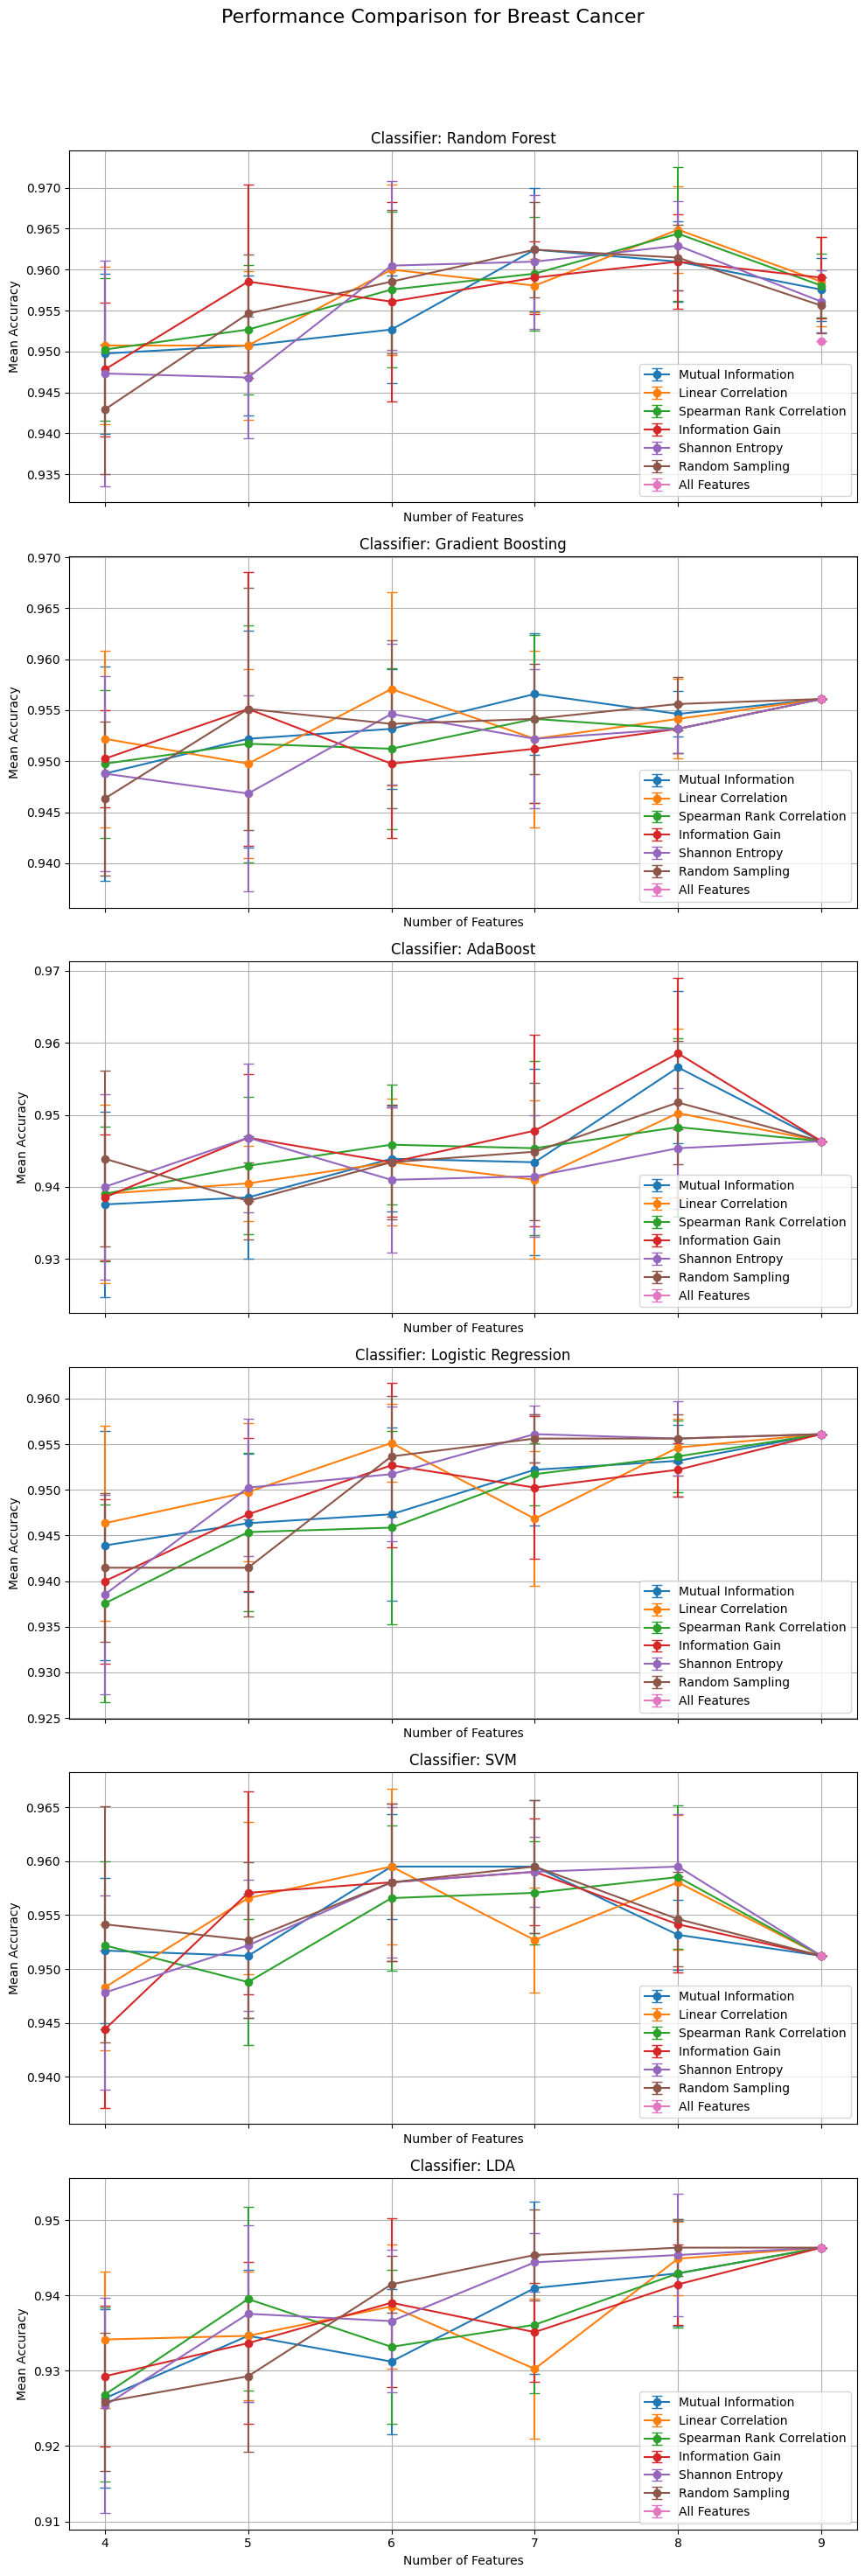

Plot saved to plots_breast_cancer.png
Generating plots for Breast Cancer Wisconsin...


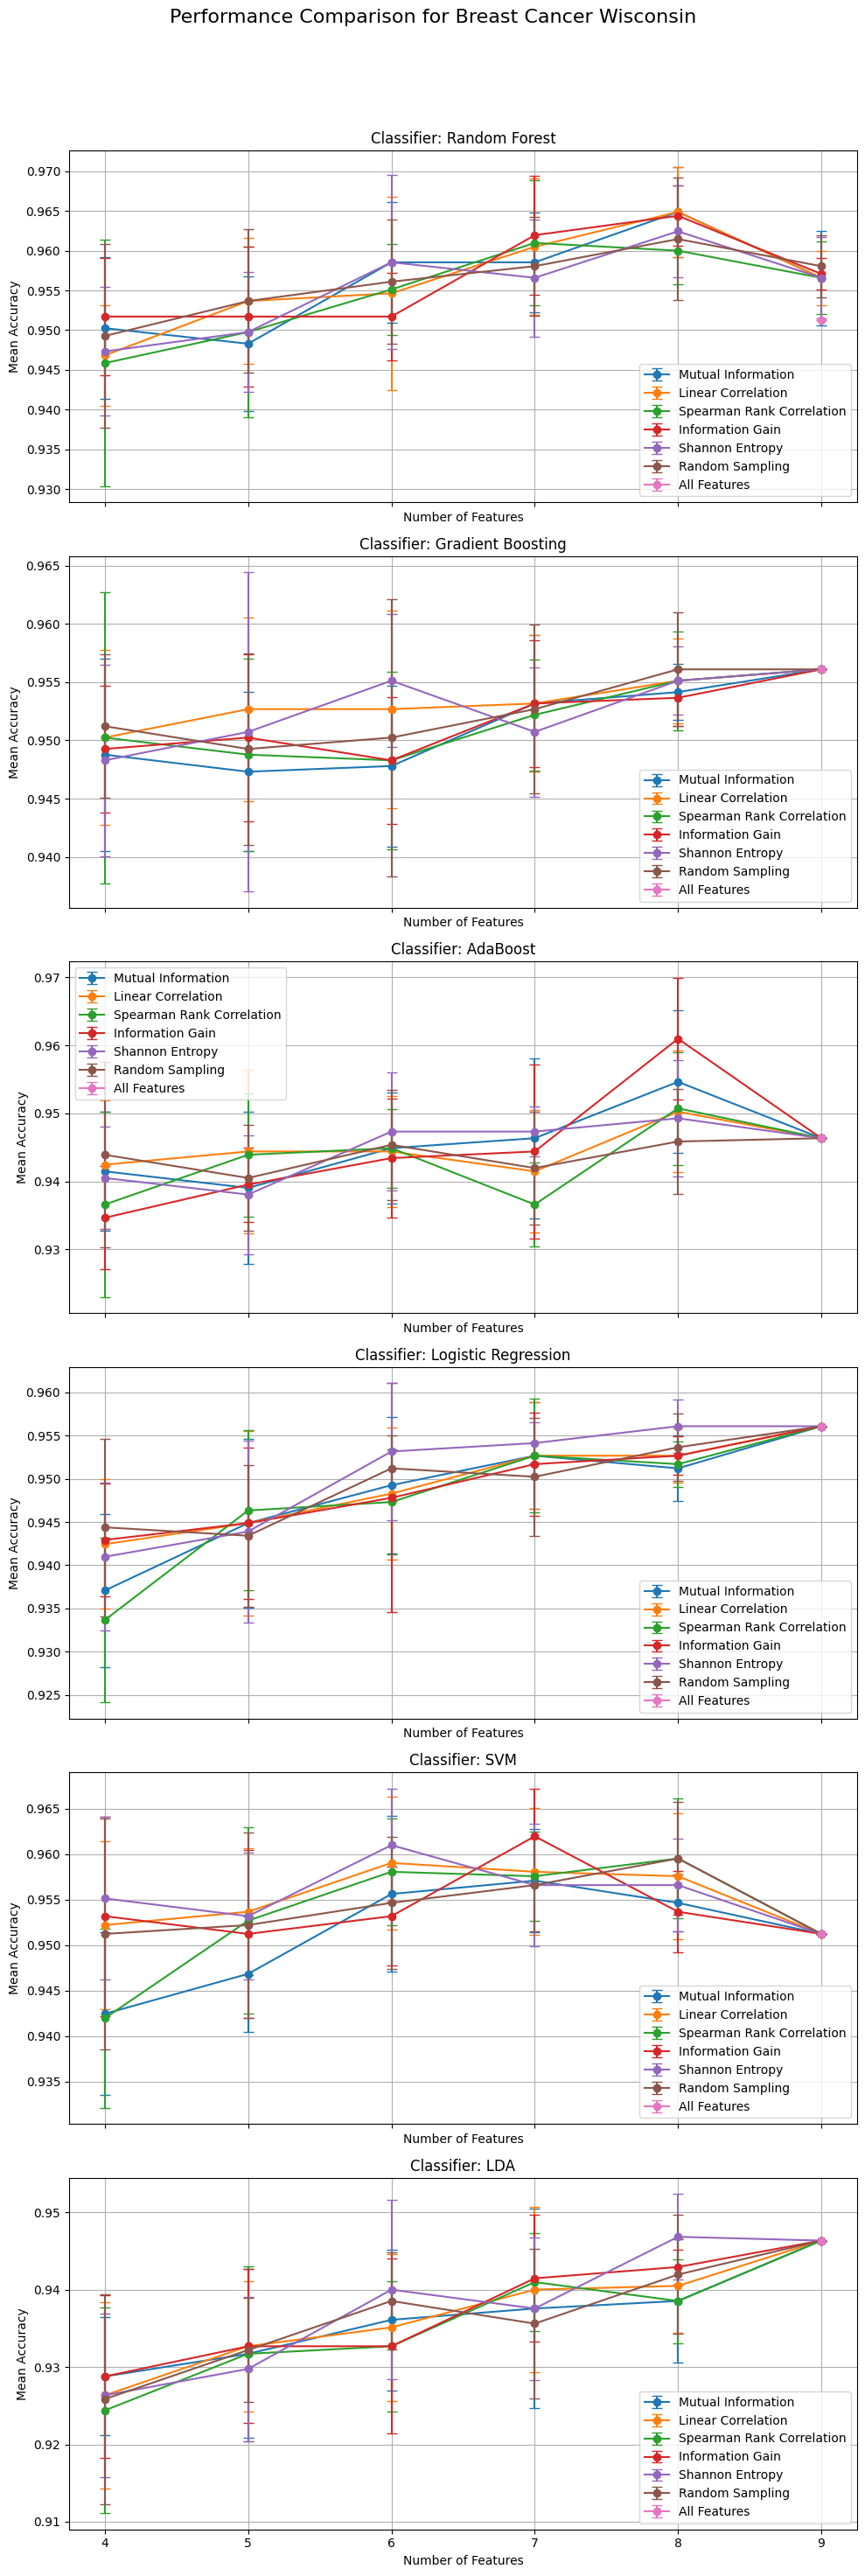

Plot saved to plots_breast_cancer_wisconsin.png
Generating plots for Diabetic Dataset...


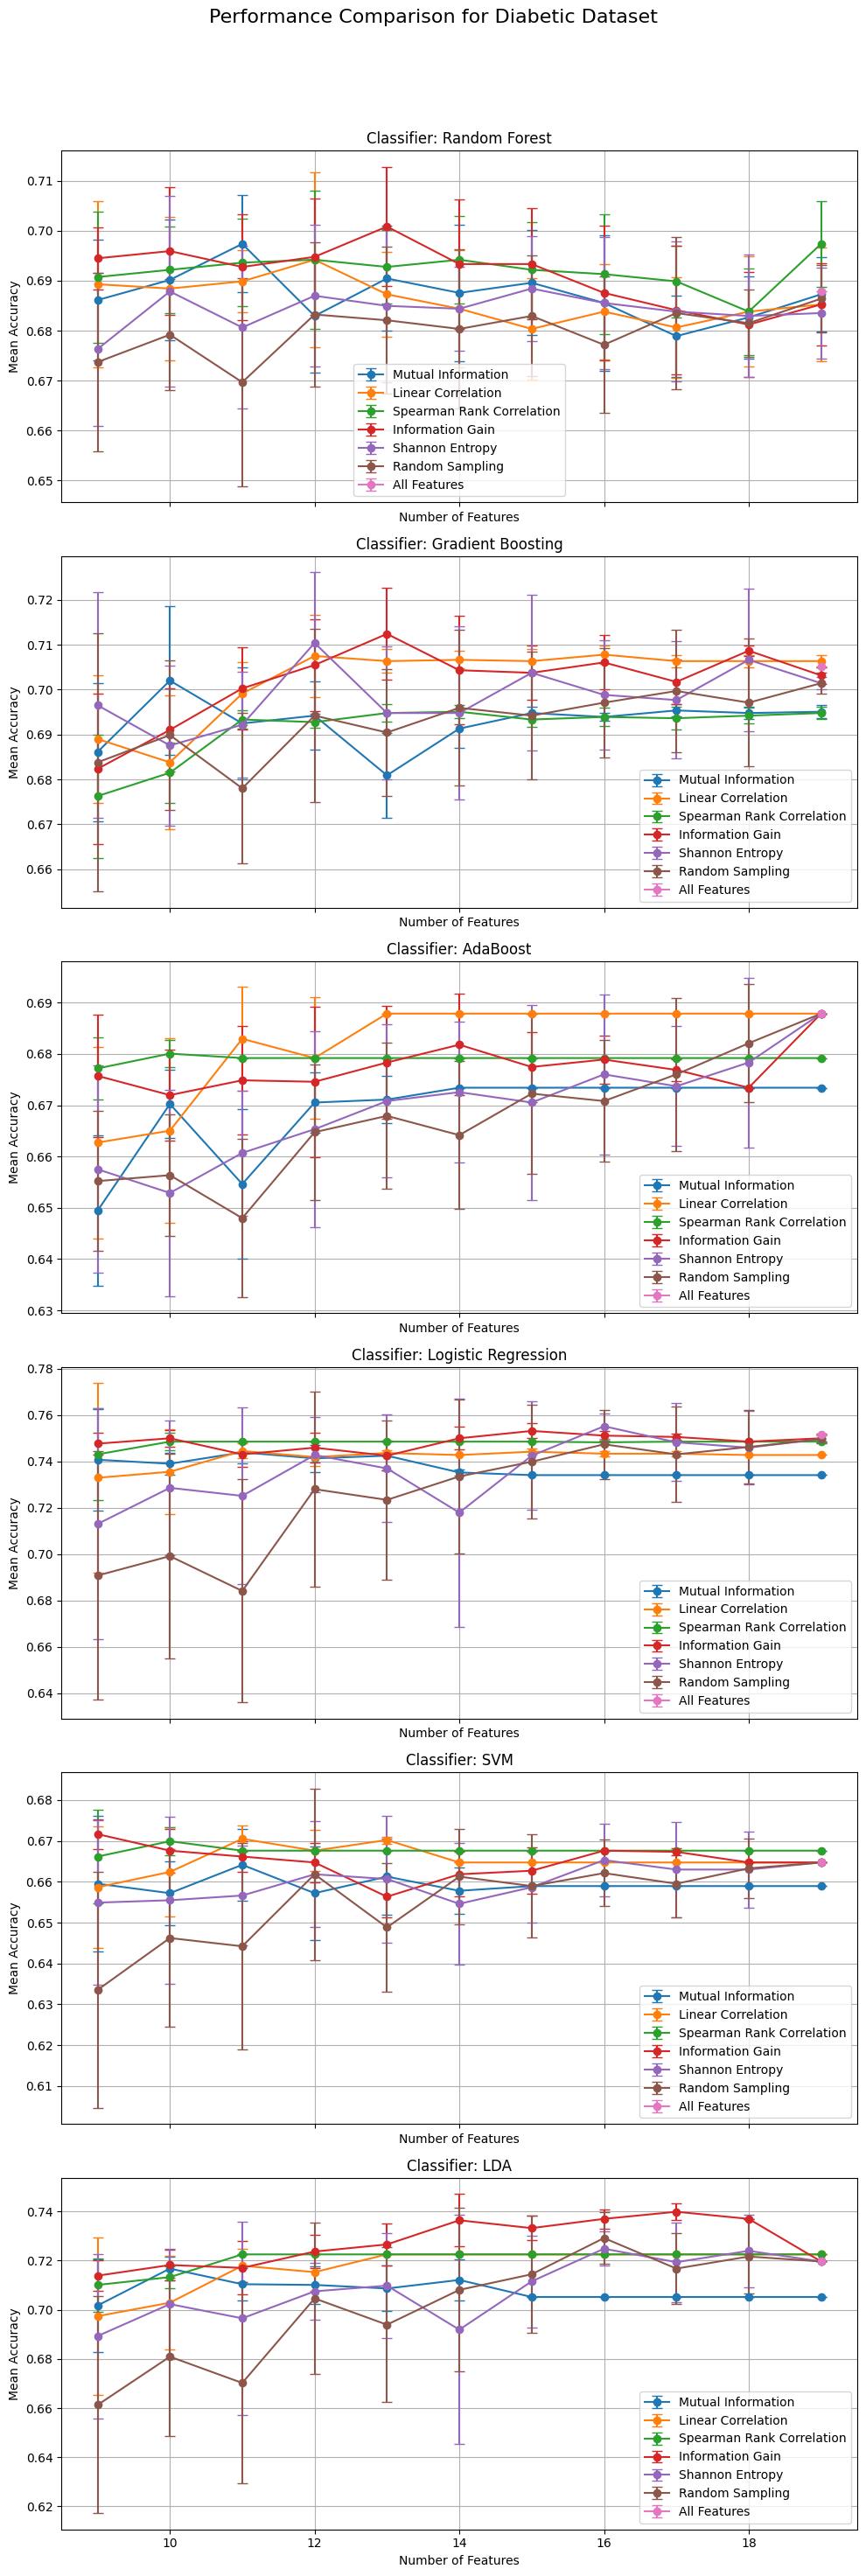

Plot saved to plots_diabetic_dataset.png
Generating plots for Heart Failure...


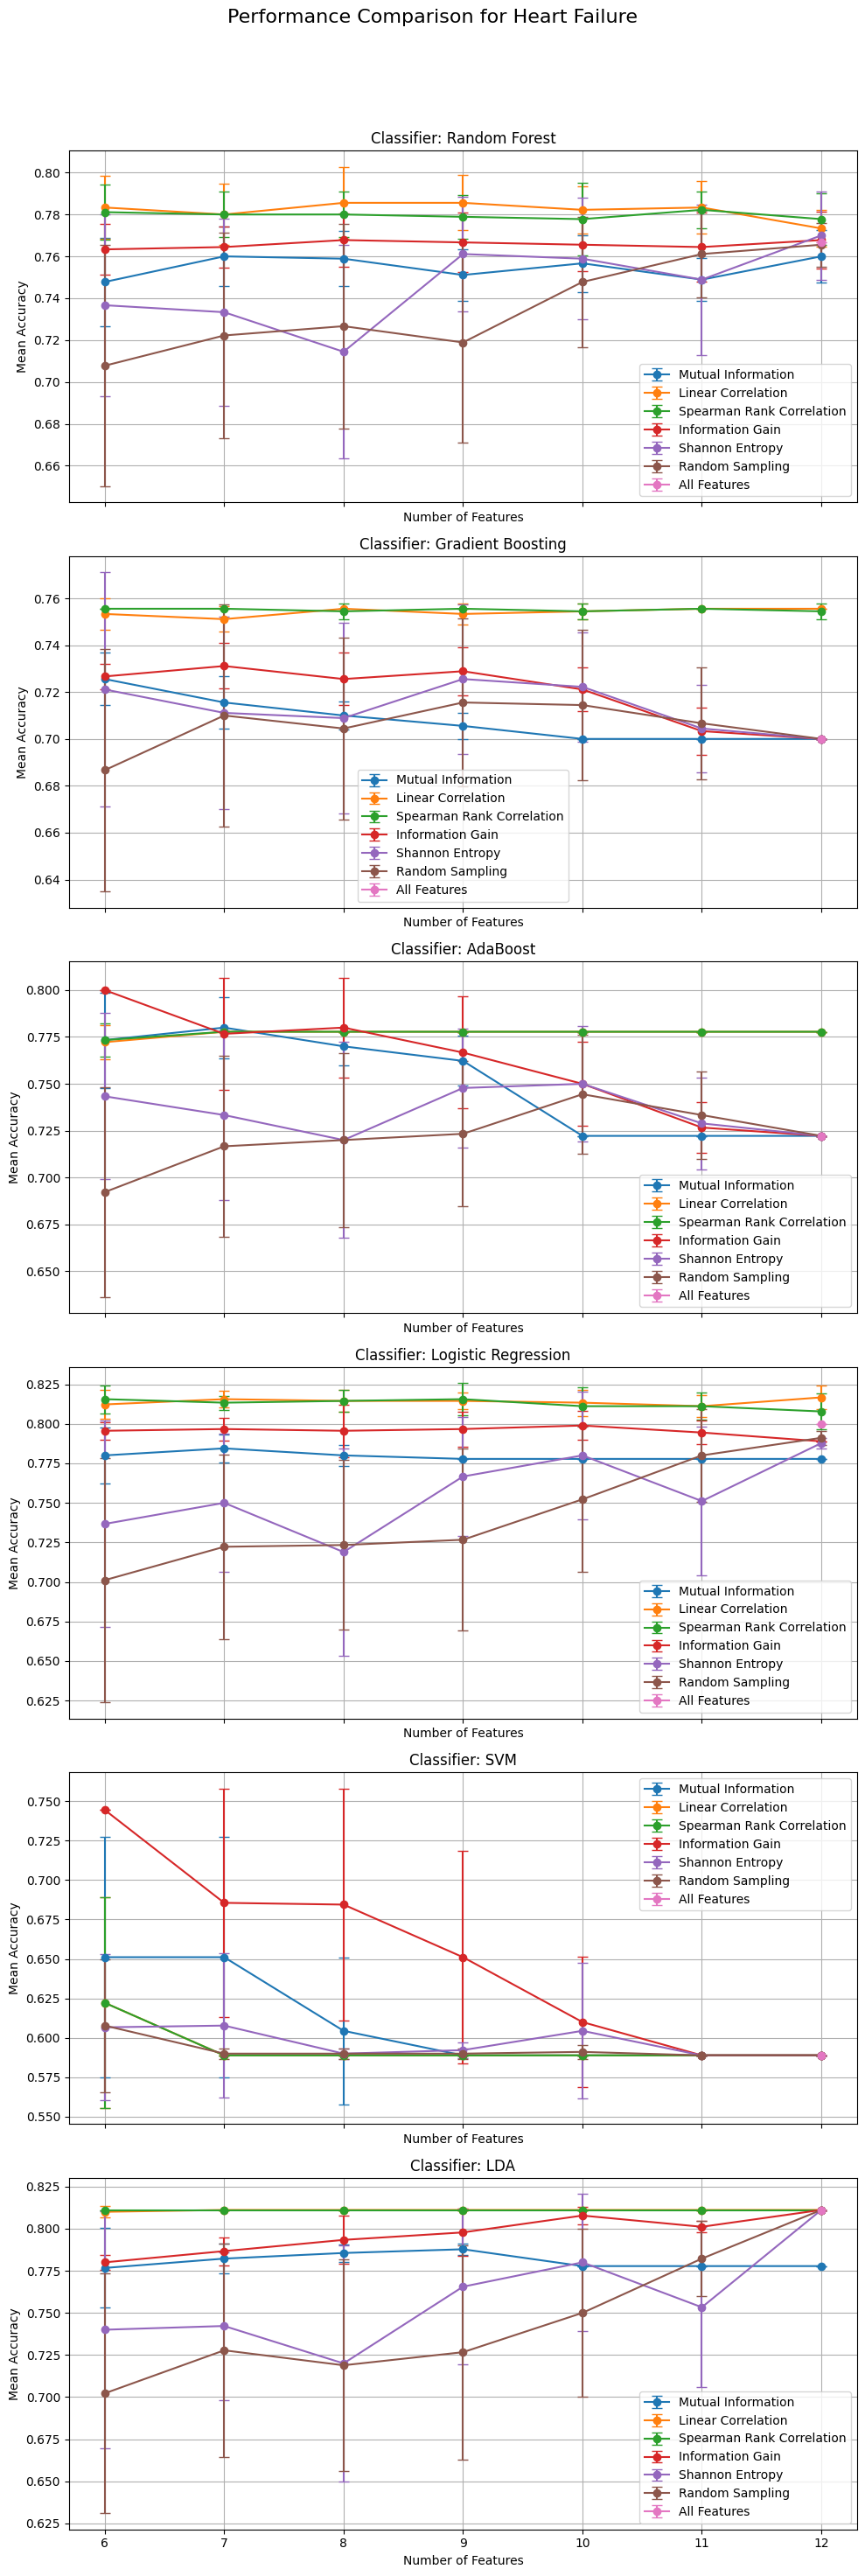

Plot saved to plots_heart_failure.png
Generating plots for Liver Disorder...


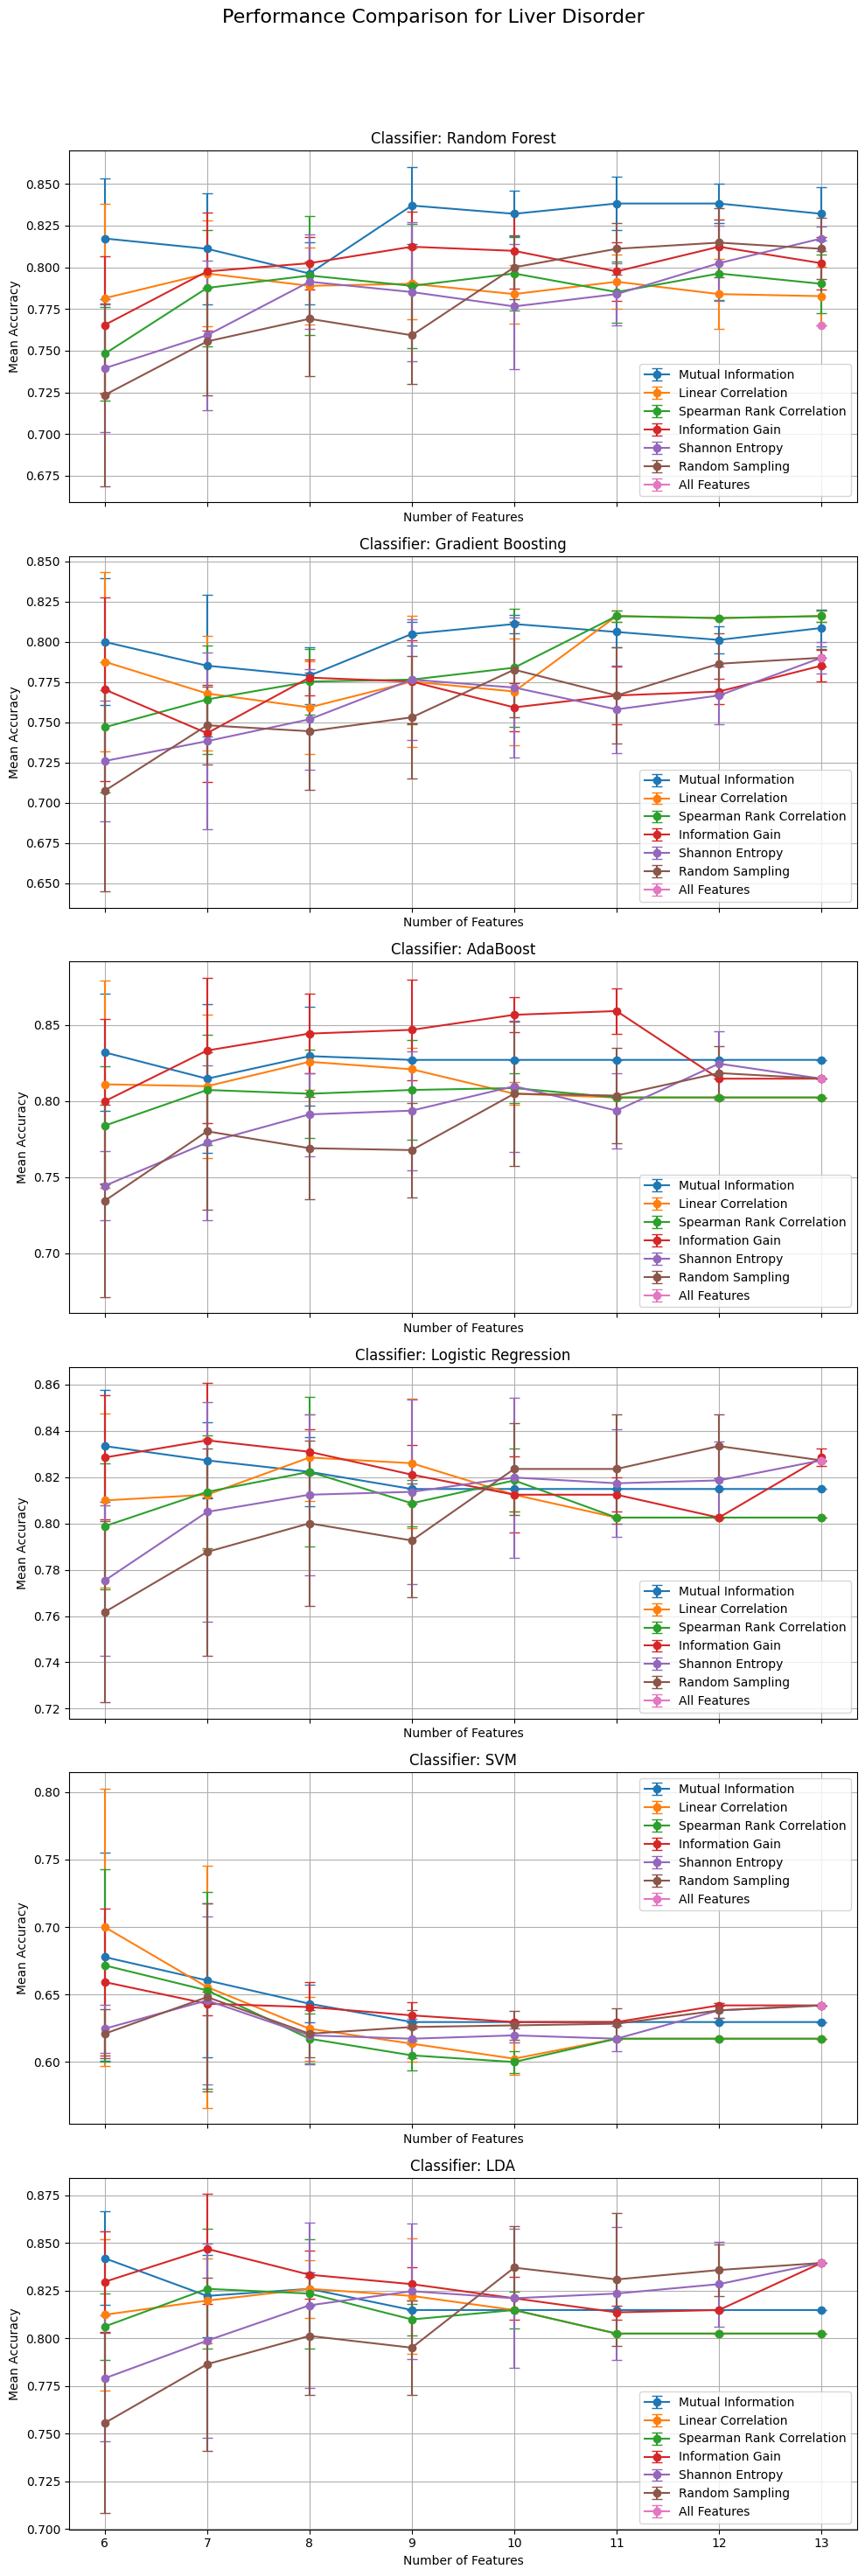

Plot saved to plots_liver_disorder.png


In [14]:
import pandas as pd
import matplotlib.pyplot as plt


files = {
    "Breast Cancer": "summary_results_breast_cancer.csv",
    "Breast Cancer Wisconsin": "summary_results_breast_cancer_wisconsin.csv",
    "Diabetic Dataset": "summary_results_diabetic_dataset.csv",
    "Heart Failure": "summary_results_heart_failure.csv",
    "Liver Disorder": "summary_results_liver_disorder.csv"
}

def plot_classifier_performance(file_path, dataset_name):

    df = pd.read_csv(file_path)


    classifiers = df["Classifier"].unique()


    fig, axes = plt.subplots(nrows=len(classifiers), ncols=1, figsize=(10, 5 * len(classifiers)), sharex=True)

    if len(classifiers) == 1:
        axes = [axes]

    for ax, classifier in zip(axes, classifiers):

        classifier_df = df[df["Classifier"] == classifier]


        for method in classifier_df["Method"].unique():
            method_df = classifier_df[classifier_df["Method"] == method]
            ax.errorbar(
                method_df["n_features"],
                method_df["Mean Accuracy"],
                yerr=method_df["Std Accuracy"],
                label=method,
                capsize=4,
                marker="o",
            )


        ax.set_title(f"Classifier: {classifier}")
        ax.set_xlabel("Number of Features")
        ax.set_ylabel("Mean Accuracy")
        ax.legend()
        ax.grid(True)

    fig.suptitle(f"Performance Comparison for {dataset_name}", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])


    output_file = f"plots_{dataset_name.replace(' ', '_').lower()}.png"
    plt.savefig(output_file)
    plt.show()
    print(f"Plot saved to {output_file}")

for dataset_name, file_path in files.items():
    print(f"Generating plots for {dataset_name}...")
    plot_classifier_performance(file_path, dataset_name)


In [15]:
import pandas as pd
from scipy.stats import ttest_rel

# List of summary result files
files = {
    "Breast Cancer": "summary_results_breast_cancer.csv",
    "Breast Cancer Wisconsin": "summary_results_breast_cancer_wisconsin.csv",
    "Diabetic Dataset": "summary_results_diabetic_dataset.csv",
    "Heart Failure": "summary_results_heart_failure.csv",
    "Liver Disorder": "summary_results_liver_disorder.csv"
}

# Function to perform paired t-tests
def perform_t_tests(df):
    methods = df["Method"].unique()
    classifiers = df["Classifier"].unique()
    t_test_results = []

    for classifier in classifiers:
        for i, method1 in enumerate(methods):
            for method2 in methods[i + 1:]:
                method1_acc = df[(df["Method"] == method1) & (df["Classifier"] == classifier)]["Mean Accuracy"]
                method2_acc = df[(df["Method"] == method2) & (df["Classifier"] == classifier)]["Mean Accuracy"]

                if len(method1_acc) == len(method2_acc) and len(method1_acc) > 1:
                    t_stat, p_value = ttest_rel(method1_acc, method2_acc)
                    t_test_results.append({
                        "Classifier": classifier,
                        "Method 1": method1,
                        "Method 2": method2,
                        "t_stat": t_stat,
                        "p_value": p_value
                    })
    return pd.DataFrame(t_test_results)

# Function to summarize the best results for each dataset
def summarize_best_results(df):
    summary = []
    for classifier in df["Classifier"].unique():
        classifier_df = df[df["Classifier"] == classifier]
        best_row = classifier_df.loc[classifier_df["Mean Accuracy"].idxmax()]
        method_type = "Probabilistic Feature Selection" if best_row["Method"] in [
            "Mutual Information", "Information Gain", "Spearman Rank Correlation", "Linear Correlation", "Shannon Entropy"
        ] else ("Random Sampling" if best_row["Method"] == "Random Sampling" else "All Features")

        summary.append({
            "Classifier": best_row["Classifier"],
            "Best Method": best_row["Method"],
            "n_features": best_row["n_features"],
            "Best Accuracy": best_row["Mean Accuracy"],
            "Std Dev": best_row["Std Accuracy"],
            "Method Type": method_type
        })
    return pd.DataFrame(summary)

# Function to summarize statistically significant t-test results
def summarize_significant_t_tests(t_test_df, alpha=0.05):
    significant_results = t_test_df[t_test_df["p_value"] < alpha]
    return significant_results

# Process each dataset
for dataset_name, file_path in files.items():
    print(f"\nProcessing dataset: {dataset_name}")

    # Load the summary result file
    df = pd.read_csv(file_path)

    # Perform paired t-tests
    t_test_results = perform_t_tests(df)
    t_test_results_file = f"t_test_results_{dataset_name.replace(' ', '_').lower()}.csv"
    t_test_results.to_csv(t_test_results_file, index=False)
    print(f"T-test results saved to {t_test_results_file}")

    # Summarize the best results
    best_results = summarize_best_results(df)
    best_results_file = f"best_results_{dataset_name.replace(' ', '_').lower()}.csv"
    best_results.to_csv(best_results_file, index=False)
    print(f"Best results saved to {best_results_file}")

    # Summarize significant t-test results
    significant_results = summarize_significant_t_tests(t_test_results)
    significant_results_file = f"significant_t_test_results_{dataset_name.replace(' ', '_').lower()}.csv"
    significant_results.to_csv(significant_results_file, index=False)
    print(f"Significant t-test results saved to {significant_results_file}")

    # Print the best results
    print(f"\nBest Results for {dataset_name}:")
    print(best_results)

    # Print the best method, n-value, and accuracy
    for index, row in best_results.iterrows():
        print(f"Dataset: {dataset_name}")
        print(f"Classifier: {row['Classifier']}")
        print(f"Best Method: {row['Best Method']}")
        print(f"n_features: {row['n_features']}")
        print(f"Mean Accuracy: {row['Best Accuracy']:.4f}")
        print(f"Std Dev: {row['Std Dev']:.4f}")
        print(f"Method Type: {row['Method Type']}")
        print("-" * 50)

    # Print statistically significant t-test results
    print(f"\nStatistically Significant Results for {dataset_name}:")
    print(significant_results)



Processing dataset: Breast Cancer
T-test results saved to t_test_results_breast_cancer.csv
Best results saved to best_results_breast_cancer.csv
Significant t-test results saved to significant_t_test_results_breast_cancer.csv

Best Results for Breast Cancer:
            Classifier         Best Method  n_features  Best Accuracy  \
0        Random Forest  Linear Correlation           8       0.964878   
1    Gradient Boosting  Linear Correlation           6       0.957073   
2             AdaBoost    Information Gain           8       0.958537   
3  Logistic Regression  Mutual Information           9       0.956098   
4                  SVM  Mutual Information           7       0.959512   
5                  LDA  Mutual Information           9       0.946341   

        Std Dev                      Method Type  
0  5.253819e-03  Probabilistic Feature Selection  
1  9.458888e-03  Probabilistic Feature Selection  
2  1.051896e-02  Probabilistic Feature Selection  
3  2.220446e-16  Probabil

In [ ]:
import pandas as pd
from scipy.stats import ttest_rel

files = {
    "Breast Cancer": "summary_results_breast_cancer.csv",
    "Breast Cancer Wisconsin": "summary_results_breast_cancer_wisconsin.csv",
    "Diabetic Dataset": "summary_results_diabetic_dataset.csv",
    "Heart Failure": "summary_results_heart_failure.csv",
    "Liver Disorder": "summary_results_liver_disorder.csv"
}

def perform_t_tests(df):
    methods = df["Method"].unique()
    classifiers = df["Classifier"].unique()
    t_test_results = []
    for classifier in classifiers:
        for i, method1 in enumerate(methods):
            for method2 in methods[i + 1:]:
                method1_acc = df[(df["Method"] == method1) & (df["Classifier"] == classifier)]["Mean Accuracy"]
                method2_acc = df[(df["Method"] == method2) & (df["Classifier"] == classifier)]["Mean Accuracy"]
                if len(method1_acc) == len(method2_acc) and len(method1_acc) > 1:
                    t_stat, p_value = ttest_rel(method1_acc, method2_acc)
                    t_test_results.append({
                        "Classifier": classifier,
                        "Method 1": method1,
                        "Method 2": method2,
                        "t_stat": t_stat,
                        "p_value": p_value
                    })
    return pd.DataFrame(t_test_results)

def summarize_best_results(df):
    summary = []
    for classifier in df["Classifier"].unique():
        classifier_df = df[df["Classifier"] == classifier]
        best_row = classifier_df.loc[classifier_df["Mean Accuracy"].idxmax()]
        method_type = "Probabilistic Feature Selection" if best_row["Method"] in [
            "Mutual Information", "Information Gain", "Spearman Rank Correlation", "Linear Correlation", "Shannon Entropy"
        ] else ("Random Sampling" if best_row["Method"] == "Random Sampling" else "All Features")
        summary.append({
            "Classifier": best_row["Classifier"],
            "Best Method": best_row["Method"],
            "n_features": best_row["n_features"],
            "Best Accuracy": best_row["Mean Accuracy"],
            "Std Dev": best_row["Std Accuracy"],
            "Method Type": method_type
        })
    return pd.DataFrame(summary)

def summarize_significant_t_tests(t_test_df, alpha=0.05):
    significant_results = t_test_df[t_test_df["p_value"] < alpha]
    return significant_results

for dataset_name, file_path in files.items():
    print(f"\nProcessing dataset: {dataset_name}")
    df = pd.read_csv(file_path)
    t_test_results = perform_t_tests(df)
    t_test_results_file = f"t_test_results_{dataset_name.replace(' ', '_').lower()}.csv"
    t_test_results.to_csv(t_test_results_file, index=False)
    print(f"T-test results saved to {t_test_results_file}")
    best_results = summarize_best_results(df)
    best_results_file = f"best_results_{dataset_name.replace(' ', '_').lower()}.csv"
    best_results.to_csv(best_results_file, index=False)
    print(f"Best results saved to {best_results_file}")
    significant_results = summarize_significant_t_tests(t_test_results)
    significant_results_file = f"significant_t_test_results_{dataset_name.replace(' ', '_').lower()}.csv"
    significant_results.to_csv(significant_results_file, index=False)
    print(f"Significant t-test results saved to {significant_results_file}")
    print(f"\nBest Results for {dataset_name}:")
    print(best_results)
    for index, row in best_results.iterrows():
        print(f"Dataset: {dataset_name}")
        print(f"Classifier: {row['Classifier']}")
        print(f"Best Method: {row['Best Method']}")
        print(f"n_features: {row['n_features']}")
        print(f"Mean Accuracy: {row['Best Accuracy']:.4f}")
        print(f"Std Dev: {row['Std Dev']:.4f}")
        print(f"Method Type: {row['Method Type']}")
        print("-" * 50)
    print(f"\nStatistically Significant Results for {dataset_name}:")
    print(significant_results)
